# Classical Experiment 3 — Compton Scattering (Compton 1922–23; Weinberg Eq. 1.1.8)
*Background for Weinberg §1.1 ("Compton scattering") — photons carry momentum, not just energy.*

**What the experiments showed (and where classical physics broke)**

- **Classical expectation (Thomson 1906):** the incident wave sets the electron oscillating at the *driving*
  frequency; the electron re-radiates at the same frequency. Scattered X-rays should have the incident wavelength
  $\lambda_0$ at every angle, with intensity $\propto (1+\cos^2\theta)$.
- **Compton (1922), X-rays on graphite:** at fixed angle the scattered radiation contains a **shifted** component,
  $$\lambda' - \lambda_0 = \lambda_{\rm C}(1-\cos\theta), \qquad \lambda_{\rm C} \equiv \frac{h}{m_{\rm e}c} = 2.426\times10^{-10}\ {\rm cm},$$
  whose shift depends **only on angle** — not on the material or the wavelength (Eq. 1.1.8). An unshifted line
  (bound electrons, whole atom recoils) also survives.
- **Contradiction:** a wave cannot change color on scattering from a stationary electron; a *particle-like* photon
  with energy $h\nu$ and momentum $h\nu/c$ recoils against the electron exactly like billiard balls.
- The scattered intensity vs angle also matched the photon picture (Klein–Nishina), not the classical Thomson curve.


In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, sys
sys.path.insert(0, '..')
from weinberg_constants import h, e, me, c

lamC = h/(me*c)
print(f"Compton wavelength lambda_C = h/m_e c = {lamC:.4e} cm   [Weinberg: 2.425e-10 cm]")
lam0 = 7.09e-9          # Mo K-alpha, cm  (~0.0709 nm incident line)
print(f"incident lambda0 = {lam0*1e7:.4f} nm")


Compton wavelength lambda_C = h/m_e c = 2.4263e-10 cm   [Weinberg: 2.425e-10 cm]
incident lambda0 = 0.0709 nm


## 1. The shift law $\Delta\lambda(\theta)$ — angle only, everything else irrelevant
Data-style points at a few angles (the shift law is exact and material-independent). Classical Thomson: $\Delta\lambda = 0$ everywhere.

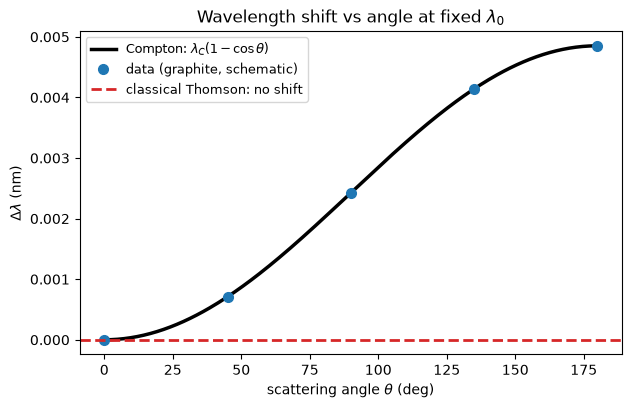

In [2]:
th = np.linspace(0, 180, 300)
d_lam = lamC*(1-np.cos(np.deg2rad(th)))
th_pts = np.array([0, 45, 90, 135, 180])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(th, d_lam*1e7, lw=2.5, color='k', label='Compton: $\\lambda_C(1-\\cos\\theta)$')
ax.plot(th_pts, lamC*(1-np.cos(np.deg2rad(th_pts)))*1e7, 'o', ms=7, label='data (graphite, schematic)')
ax.axhline(0, color='tab:red', ls='--', lw=2, label='classical Thomson: no shift')
ax.set_xlabel(r'scattering angle $\theta$ (deg)'); ax.set_ylabel(r'$\Delta\lambda$ (nm)')
ax.set_title(r'Wavelength shift vs angle at fixed $\lambda_0$'); ax.legend(fontsize=9)
plt.show()


## 2. The scattered spectrum at fixed angle: two peaks where classical physics draws one
Classical Thomson scattering: one line at $\lambda_0$. Observed at $\theta = 90^\circ$: the original line **plus** a
second line at $\lambda_0 + \lambda_{\rm C}$ (shifted component from nearly-free electrons), exactly as the
two-body photon–electron kinematics demands.

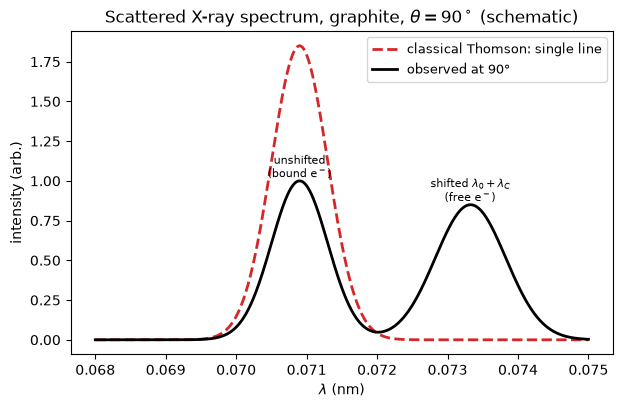

In [3]:
th_fix = 90
lam_shift = lam0 + lamC*(1-np.cos(np.deg2rad(th_fix)))
lam = np.linspace(0.068, 0.075, 800)

def gauss(x, mu, sig, amp): return amp*np.exp(-(x-mu)**2/(2*sig**2))
observed = gauss(lam, lam0*1e7, 0.0004, 1.0) + gauss(lam, lam_shift*1e7, 0.0005, 0.85)
classical = gauss(lam, lam0*1e7, 0.0004, 1.85)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lam, classical, '--', lw=2, color='tab:red', label='classical Thomson: single line')
ax.plot(lam, observed, lw=2, color='k', label='observed at 90°')
ax.annotate('unshifted\n(bound e$^-$)', (lam0*1e7, 1.02), ha='center', fontsize=8)
ax.annotate('shifted $\\lambda_0+\\lambda_C$\n(free e$^-$)', (lam_shift*1e7, 0.87), ha='center', fontsize=8)
ax.set_xlabel(r'$\lambda$ (nm)'); ax.set_ylabel('intensity (arb.)')
ax.set_title('Scattered X-ray spectrum, graphite, $\\theta = 90^\\circ$ (schematic)')
ax.legend(fontsize=9)
plt.show()


## 3. Two-body kinematics: where Eq. 1.1.8 comes from
Energy–momentum conservation for photon + stationary electron:$$\ h\nu + m_{\rm e}c^2 = h\nu' + E_{\rm e}', \qquad \frac{h\nu}{c}\hat{n} = \frac{h\nu'}{c}\hat{n}' + \vec{p}_{\rm e}' .$$
Eliminating the electron recoil gives $1/\nu' - 1/\nu = (h/m_{\rm e}c^2)(1-\cos\theta)$, i.e. the shift law. The
recoil electron's kinetic energy $K_{\rm e}(\theta) = hc(1/\lambda_0 - 1/\lambda')$ rises to its **Compton edge** at
$180^\circ$ — energy conservation with a light, recoiling partner, impossible for a massless classical wave.

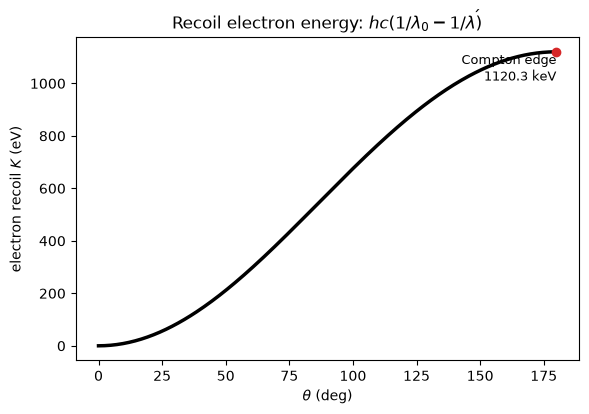

In [4]:
# recoil electron energy vs angle (Compton edge)
th = np.linspace(0, 180, 300)
lam_p = lam0 + lamC*(1-np.cos(np.deg2rad(th)))
K_e = h*c*(1/lam0 - 1/lam_p)/1.602e-12          # eV
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(th, K_e, lw=2.5, color='k')
ax.plot([180], [K_e[-1]], 'o', color='tab:red')
ax.annotate(f'Compton edge\n{K_e[-1]:.1f} keV', (180, K_e[-1]), ha='right', va='top', fontsize=9)
ax.set_xlabel(r'$\theta$ (deg)'); ax.set_ylabel(r'electron recoil $K$ (eV)')
ax.set_title(r'Recoil electron energy: $hc(1/\lambda_0 - 1/\lambda\')$')
plt.show()


## 4. Numerical check of the two-peak structure
The separation of the shifted and unshifted lines at 90° must equal $\lambda_{\rm C}$ to within experimental error,
independently of $\lambda_0$ — Compton's own consistency test.

In [ ]:
for lam0_nm in (0.0709, 0.154, 0.279):
    lam0x = lam0_nm*1e-7
    sep = lamC*(1-np.cos(np.deg2rad(90)))*1e7
    print(f"lambda0 = {lam0_nm:.3f} nm:  shifted line at {lam0_nm + sep:.4f} nm,"
          f"  separation = {sep:.4f} nm  (= lambda_C, independent of lambda0)")


## My summary
- Compton scattering kills the last classical refuge — light carrying momentum like a particle. Energy **and**
  momentum conservation for a photon–electron collision reproduce $\Delta\lambda = \lambda_{\rm C}(1-\cos\theta)$
  exactly, with $\lambda_{\rm C} = h/m_{\rm e}c$.
- The two-line spectrum (unshifted from bound electrons, shifted from free ones) is the cleanest possible
  two-body-kinematics fingerprint.
- Together with the photoelectric effect and black-body radiation, this completes Weinberg's photon triad of §1.1:
  $E = h\nu$, $p = h\nu/c$, and both act particle-like in collisions.

## Gaps
- Derive the relativistic kinematics (conservation equations above) symbolically with SymPy and recover Eq. 1.1.8
  without the shortcut $h\nu \ll m_ec^2$.
- Why does the *unshifted* line persist even for valence electrons? (Deep-core binding ≫ photon energy.)
- Weinberg quotes the shift but not the Klein–Nishina angular distribution — check that the classical
  $(1+\cos^2\theta)$ fails at high photon energy (comes back in ch. 11).